<h1 style="color:#8B0000;">CIFAR-10 EDA and data pipeline (SimCLR project)</h1>

<h3 style="color:#8B0000;">Setup</h3>

Imports and file paths. Change the paths if your folders are named differently. Torch is loaded later, in Part 3.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Folder and file names
CSV_PATH = "trainLabels.csv"
TRAIN_DIR = "train"
TEST_DIR = "test"

# Fixed seed so we get the same random results every run
SEED = 42
np.random.seed(SEED)

<h1 style="color:#8B0000; border-bottom:2px solid #8B0000; padding-bottom:4px;">2. Exploratory Data Analysis</h1>

<h3 style="color:#8B0000;">2.1 Dataset size and class balance</h3>

How many images and classes are there, and are the classes balanced?

Total images: 50000
Number of classes: 10
Images per class:
label
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64
Imbalance ratio (largest / smallest): 1.0
Random guessing accuracy: 10%


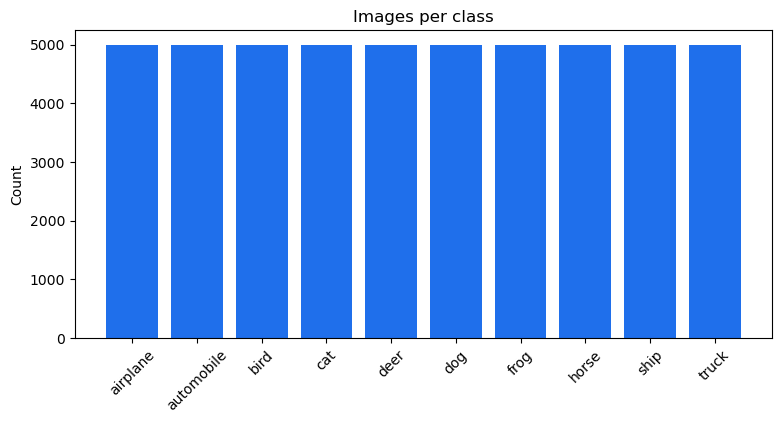

In [2]:
df = pd.read_csv(CSV_PATH)
classes = sorted(df["label"].unique())
counts = df["label"].value_counts().reindex(classes)

print("Total images:", len(df))
print("Number of classes:", len(classes))
print("Images per class:")
print(counts)
print("Imbalance ratio (largest / smallest):", counts.max() / counts.min())
print("Random guessing accuracy: %.0f%%" % (100 / len(classes)))

plt.figure(figsize=(9, 4))
plt.bar(counts.index, counts.values, color="#1f6feb")
plt.title("Images per class")
plt.xticks(rotation=45)
plt.ylabel("Count")
plt.show()

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> 50,000 images in 10 classes, 5,000 each, so the classes are perfectly balanced. Plain accuracy is a fair metric here, and random guessing would get 10%.
</div>

<h3 style="color:#8B0000;">2.2 Check the data is clean</h3>

Look for missing values, duplicate ids and broken image files, and load all images into one array called <code>X</code>.

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

X = np.zeros((len(df), 32, 32, 3), dtype=np.uint8)
bad = 0

for i in range(len(df)):
    path = TRAIN_DIR + "/" + str(df["id"][i]) + ".png"
    try:
        X[i] = np.array(Image.open(path).convert("RGB"))
    except Exception:
        bad = bad + 1

print("Missing or broken images:", bad)

# Turn class names into numbers (0 to 9)
y = df["label"].map({name: n for n, name in enumerate(classes)}).values

# The Kaggle test folder has no public labels, so we cannot score on it
if os.path.isdir(TEST_DIR):
    print("Images in the test folder:", len(os.listdir(TEST_DIR)))

Missing values: 0
Duplicate ids: 0
Missing or broken images: 0
Images in the test folder: 300000


<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> No missing values, no duplicate ids and no broken images, so the data is clean. The Kaggle test folder has 300,000 images but no labels, so we can't score on it. Part 3 uses the official 10,000-image test set instead.
</div>

<h3 style="color:#8B0000;">2.3 Look at the images</h3>

Five random images from each class.

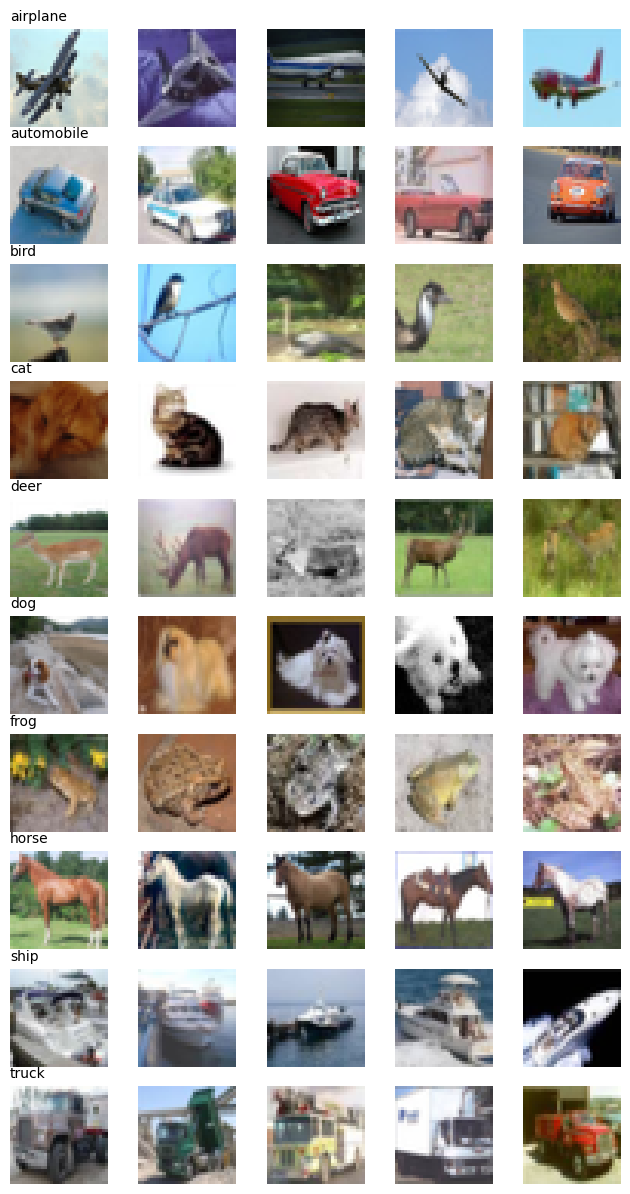

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(8, 15))

for row in range(10):
    ids = np.where(y == row)[0]
    chosen = np.random.choice(ids, 5, replace=False)
    for col in range(5):
        axes[row, col].imshow(X[chosen[col]])
        axes[row, col].axis("off")
    axes[row, 0].set_title(classes[row], loc="left", fontsize=10)

plt.show()

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Images of the same class look very different (pose, zoom, background, colour). Many classes share a typical background, like sky for airplanes and water for ships. The images are small and blurry, so the model has to learn the shape of the object. That is why augmentation matters.
</div>

<h3 style="color:#8B0000;">2.4 Pixel statistics</h3>

Pixel range and the mean and std of each colour. We use these to normalise the images in Part 3.

In [7]:
print("Pixel values go from", X.min(), "to", X.max())

mean = X.mean(axis=(0, 1, 2)) / 255
std = X.std(axis=(0, 1, 2)) / 255
print("Mean (R, G, B):", mean.round(3))
print("Std  (R, G, B):", std.round(3))

Pixel values go from 0 to 255
Mean (R, G, B): [0.491 0.482 0.447]
Std  (R, G, B): [0.247 0.243 0.262]


<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Pixel values go from 0 to 255. The mean is 0.491, 0.482, 0.447 (R, G, B) and the std is 0.247, 0.243, 0.262.
</div>

<h3 style="color:#8B0000;">2.5 Brightness and colour by class</h3>

Brightness (average pixel value) and average colour for each class.

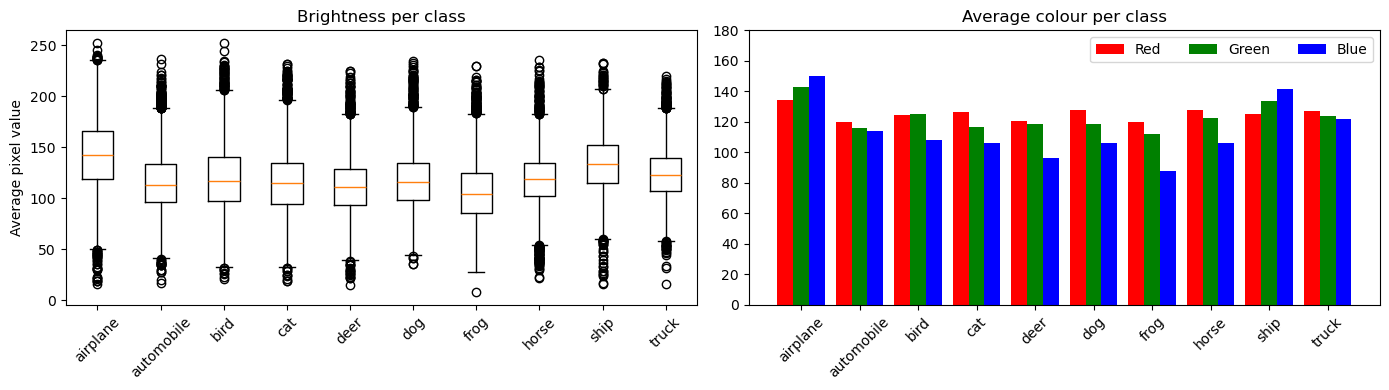

                R      G      B  median brightness
airplane    134.0  142.9  150.2              142.2
automobile  120.2  115.9  114.0              113.0
bird        124.8  125.3  108.1              117.3
cat         126.3  116.4  106.0              115.1
deer        120.3  118.6   96.4              110.8
dog         127.5  118.5  106.2              115.9
frog        119.9  111.8   88.0              104.1
horse       128.0  122.4  106.3              118.9
ship        125.0  134.0  141.4              133.3
truck       127.2  123.8  121.9              122.6


In [8]:
# Brightness of every image
brightness = X.mean(axis=(1, 2, 3))

# Average red, green and blue of each class
colour_means = []
for n in range(10):
    colour_means.append(X[y == n].mean(axis=(0, 1, 2)))
colour_means = np.array(colour_means)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Left: brightness boxplot per class
ax[0].boxplot([brightness[y == n] for n in range(10)])
ax[0].set_xticks(range(1, 11))
ax[0].set_xticklabels(classes, rotation=45)
ax[0].set_title("Brightness per class")
ax[0].set_ylabel("Average pixel value")

# Right: average colour per class
positions = np.arange(10)
ax[1].bar(positions - 0.27, colour_means[:, 0], width=0.27, color="red", label="Red")
ax[1].bar(positions, colour_means[:, 1], width=0.27, color="green", label="Green")
ax[1].bar(positions + 0.27, colour_means[:, 2], width=0.27, color="blue", label="Blue")
ax[1].set_xticks(positions)
ax[1].set_xticklabels(classes, rotation=45)
ax[1].set_ylim(0, 180)
ax[1].legend(loc="upper right", ncol=3)
ax[1].set_title("Average colour per class")

plt.tight_layout()
plt.show()

# Exact numbers
table = pd.DataFrame(colour_means, index=classes, columns=["R", "G", "B"]).round(1)
table["median brightness"] = pd.Series(brightness).groupby(df["label"].values).median().round(1)
print(table)

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Airplane (median 142) and ship (133) are the brightest classes, and frog is the darkest (104). Airplane and ship are also the only classes where blue is the strongest colour. Every class has some very dark and very bright images. They are real photos, so we keep them. The classes overlap a lot in brightness, but colour does carry some information about the class. The paper (Section 3.1) describes a related shortcut: two crops of the same image have a similar colour histogram, so a network can match them by colour. Colour jitter and random grayscale are there to stop this.
</div>

<h3 style="color:#8B0000;">2.6 PCA and a simple baseline</h3>

PCA on 5,000 random images, plotted in 2D, then a basic kNN model on the PCA numbers as a baseline.

Variance kept by first 2 components: 40.5%
Variance kept by all 50 components : 84.5%


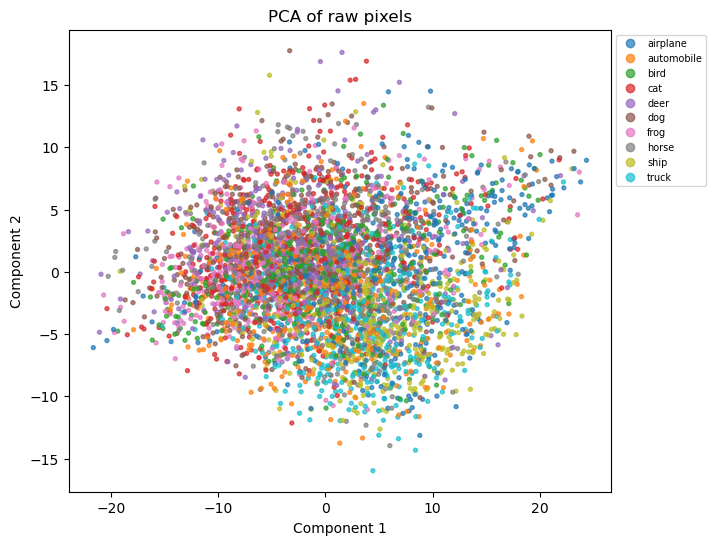

Random guessing: 10%
kNN accuracy: 30.8%


In [9]:
# Use 5000 random images
np.random.seed(SEED)
pick = np.random.choice(len(X), min(5000, len(X)), replace=False)
pixels = X[pick].reshape(len(pick), -1) / 255
labels = y[pick]

pca = PCA(n_components=50, random_state=SEED)
Z = pca.fit_transform(pixels)

print("Variance kept by first 2 components: %.1f%%" % (pca.explained_variance_ratio_[:2].sum() * 100))
print("Variance kept by all 50 components : %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

plt.figure(figsize=(7, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=8, alpha=0.7)
plt.legend(scatter.legend_elements()[0], classes, fontsize=7, bbox_to_anchor=(1, 1))
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("PCA of raw pixels")
plt.show()

# Baseline: kNN on the 50 PCA numbers (80 percent to learn, 20 percent to test)
Z_train, Z_test, y_train, y_test = train_test_split(Z, labels, test_size=0.2, stratify=labels, random_state=SEED)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Z_train, y_train)

print("Random guessing: 10%")
print("kNN accuracy: %.1f%%" % (knn.score(Z_test, y_test) * 100))

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> The first two components keep only about 40% of the information, and the classes overlap heavily, so raw pixels don't separate them. kNN gets about 31% (random is 10%). This is the number our model should beat. It is tested on part of the training data, so the final score will use the official test set.
</div>

<h3 style="color:#8B0000;">2.7 Evaluation metrics</h3>

**Main metric:** top-1 accuracy on the official 10,000-image test set. The classes are balanced, so accuracy is not misleading. It is also what the paper uses: a linear classifier is trained on the frozen encoder and scored on the test set. Random guessing gives 10%.

**Extra metrics:** per-class precision, recall and F1 (and macro-F1), plus a confusion matrix, to see which classes get mixed up. These are our additions. The paper reports top-1 accuracy.

**Not used:** top-5 accuracy (there are only 10 classes) and metrics for imbalanced data (ours is balanced).

**For comparison:** the best CIFAR-10 result in the paper is 94.0% (ResNet-50, batch size 1024, Appendix B.9). Our planned setup is different (ResNet-18, batch size 256, fewer epochs), so the numbers won't be directly comparable. In the data-fraction experiment, every run is scored on the same test set with the same metrics.

<h3 style="color:#8B0000;">2.8 Challenges and what we do about them</h3>

- Small, blurry images with a lot of variety inside each class. We use strong augmentation (3.2).
- Brightness and colour are linked to the class. We use colour jitter and random grayscale, as in the paper (3.2).
- Raw pixels don't separate the classes (PCA overlap, kNN about 31%). We need a learned encoder.
- With batch size 256, each image has 2 x 255 = 510 negatives (paper, Section 2.1), and about 10% of them (around 51) are from the same class. We didn't find this discussed in the paper, so we will mention it when we explain our results.
- The Kaggle test labels are not public. We use the official test set (3.5).
- The data-fraction experiment needs fair subsets. We use stratified sampling with a fixed seed (3.6).

The data itself is clean. The only anomalies are very dark and very bright photos, which are real images.

<h1 style="color:#8B0000; border-bottom:2px solid #8B0000; padding-bottom:4px;">3. Data Loading and Preprocessing Pipeline</h1>

<h3 style="color:#8B0000;">3.1 Environment</h3>

Load PyTorch, pick the device (cuda, mps or cpu) and set the seed.

In [10]:
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, datasets

# Seed torch too, so shuffling and augmentations are repeatable
torch.manual_seed(SEED)

# Pick the best device available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("torch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device in use:", device)

torch 2.14.1 | torchvision 0.29.1
Device in use: mps


<h3 style="color:#8B0000;">3.2 Preprocessing and augmentation</h3>

Normalisation with our own mean and std from 2.4, and the SimCLR augmentations. The crop, colour and grayscale settings follow the paper's CIFAR-10 setup (Appendix A and B.9). Training uses random augmentations, evaluation only normalises.

In [11]:
# Normalisation values measured in section 2.4
MEAN = tuple(float(v) for v in mean)
STD = tuple(float(v) for v in std)

# Training transform: one random augmented view of an image
simclr_transform = transforms.Compose([
    # Random crop covering 8 to 100 percent of the image area, resized back to 32x32
    transforms.RandomResizedCrop(32, scale=(0.08, 1.0)),
    # Flip left-right half of the time
    transforms.RandomHorizontalFlip(p=0.5),
    # Colour jitter with strength 0.5 (0.8 x 0.5 = 0.4, hue 0.2 x 0.5 = 0.1), applied 80 percent of the time
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    # Turn gray 20 percent of the time
    transforms.RandomGrayscale(p=0.2),
    # Picture to tensor with values between 0 and 1
    transforms.ToTensor(),
    # Centre and scale each colour channel
    transforms.Normalize(MEAN, STD),
])

# Evaluation transform: no augmentation, only normalisation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print("Normalisation mean:", [round(v, 3) for v in MEAN])
print("Normalisation std :", [round(v, 3) for v in STD])

Normalisation mean: [0.491, 0.482, 0.447]
Normalisation std : [0.247, 0.243, 0.262]


<h3 style="color:#8B0000;">3.3 Dataset and DataLoader for pretraining</h3>

A dataset that gives two random views of each image (a positive pair), and a DataLoader with batch size 256.

In [12]:
class ArrayDataset(Dataset):
    """Wraps the image array. Gives two views per image if two_views is True, otherwise one view."""

    def __init__(self, images, labels, transform, two_views=False):
        self.images = images
        self.labels = labels
        self.transform = transform
        self.two_views = two_views

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        # Turn the stored array back into a picture so torchvision can augment it
        img = Image.fromarray(self.images[i])
        label = int(self.labels[i])
        if self.two_views:
            # Two independent random augmentations of the same image (a positive pair)
            return self.transform(img), self.transform(img), label
        return self.transform(img), label

# Batch size from our proposal. The paper uses 4096 by default on ImageNet and 256 to 4096 on CIFAR-10.
BATCH_SIZE = 256

pretrain_set = ArrayDataset(X, y, simclr_transform, two_views=True)

# num_workers=0 works everywhere. On Colab or Linux, try 2 to 4 to load faster.
# drop_last=True keeps every batch the same size, so every image has the same number of negatives.
pretrain_loader = DataLoader(pretrain_set, batch_size=BATCH_SIZE, shuffle=True,
                             num_workers=0, drop_last=True)

print("Images:", len(pretrain_set))
print("Batches per epoch:", len(pretrain_loader))

Images: 50000
Batches per epoch: 195


<h3 style="color:#8B0000;">3.4 Check one batch</h3>

Take one batch, check the shapes and values, and look at a few pairs.

View 1 shape: (256, 3, 32, 32)
View 2 shape: (256, 3, 32, 32)
Value range : -1.99 to 2.13


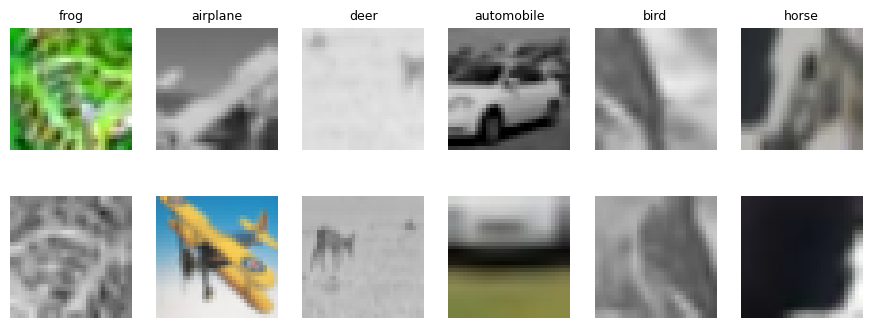

In [13]:
view1, view2, batch_labels = next(iter(pretrain_loader))

print("View 1 shape:", tuple(view1.shape))
print("View 2 shape:", tuple(view2.shape))
print("Value range : %.2f to %.2f" % (view1.min().item(), view1.max().item()))

# Undo the normalisation so the pictures can be shown
def show(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for k in range(6):
    axes[0, k].imshow(show(view1[k]))
    axes[1, k].imshow(show(view2[k]))
    axes[0, k].set_title(classes[int(batch_labels[k])], fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.show()

<h3 style="color:#8B0000;">3.5 Labelled data for linear evaluation</h3>

After pretraining we train a linear classifier on the frozen encoder, so we need labelled images with no augmentation. The test set is the official 10,000 images. If it can't be downloaded, we hold out 10% of the training images instead.

In [14]:
# Training images for the linear classifier: no augmentation
train_set = ArrayDataset(X, y, eval_transform)

try:
    # Official labelled test set. It downloads once into ./data
    test_set = datasets.CIFAR10(root="./data", train=False, download=True, transform=eval_transform)
    print("Official test set loaded:", len(test_set), "images")
    # Class numbers must match ours (both are in alphabetical order)
    print("Class order matches:", list(test_set.classes) == classes)
except Exception as error:
    # Fallback: hold out 10 percent of the training images, the same share from every class
    print("Could not load the official test set:", error)
    train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.1, stratify=y, random_state=SEED)
    test_set = Subset(train_set, test_idx)
    train_set = Subset(train_set, train_idx)
    print("Using a hold-out split instead. Label any results from it as such.")

train_loader = DataLoader(train_set, batch_size=256, shuffle=True, num_workers=0)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=0)

print("Training images:", len(train_set))
print("Test images    :", len(test_set))

Official test set loaded: 10000 images
Class order matches: True
Training images: 50000
Test images    : 10000


<h3 style="color:#8B0000;">3.6 Data-fraction subsets</h3>

A function that picks the same fraction of images from every class, for the data-fraction experiment. The exact fractions will be set from our compute budget, so the list here is just an example. The printout checks the class balance and the average brightness.

In [15]:
def stratified_subset(labels, fraction, seed=SEED):
    """Pick the same fraction of images from every class (at least 1 per class)."""
    rng = np.random.RandomState(seed)
    chosen = []
    for n in range(10):
        ids = np.where(labels == n)[0]
        how_many = max(1, int(len(ids) * fraction))
        chosen.extend(rng.choice(ids, how_many, replace=False))
    return np.array(chosen)

print("Full dataset brightness: %.1f" % brightness.mean())
for fraction in [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]:
    idx = stratified_subset(y, fraction)
    per_class = np.bincount(y[idx], minlength=10)
    print("Fraction", fraction, "-> images:", len(idx),
          "| per class:", per_class.min(), "to", per_class.max(),
          "| brightness: %.1f" % brightness[idx].mean())

# Example: a pretraining loader that uses only 10 percent of the data
subset_loader = DataLoader(Subset(pretrain_set, stratified_subset(y, 0.10)),
                           batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
print("Batches per epoch on 10 percent:", len(subset_loader))

Full dataset brightness: 120.7
Fraction 0.01 -> images: 500 | per class: 50 to 50 | brightness: 121.8
Fraction 0.05 -> images: 2500 | per class: 250 to 250 | brightness: 121.3
Fraction 0.1 -> images: 5000 | per class: 500 to 500 | brightness: 120.9
Fraction 0.25 -> images: 12500 | per class: 1250 to 1250 | brightness: 120.9
Fraction 0.5 -> images: 25000 | per class: 2500 to 2500 | brightness: 120.8
Fraction 1.0 -> images: 50000 | per class: 5000 to 5000 | brightness: 120.7
Batches per epoch on 10 percent: 19


<h3 style="color:#8B0000;">3.7 What we changed from the paper and the official code</h3>

The official code is written in TensorFlow, and the paper trained on Cloud TPUs. We only use them as a reference. This pipeline is our own PyTorch code. The colour settings come from the PyTorch snippet in the paper's Appendix A, which may not match the TensorFlow code exactly.

**Same as the paper (CIFAR-10, Appendix A and B.9):** random crop of 8 to 100% of the area, random flip, colour jitter with strength 0.5 (applied 80% of the time), grayscale 20% of the time, no Gaussian blur.

**Different:**
- PyTorch instead of TensorFlow, so it runs on Colab or a laptop.
- Batch size 256 (our proposal). The paper's CIFAR-10 runs use 256 to 4096.
- Official test set through torchvision, with a hold-out fallback.

**Planned, not built yet (from our proposal):**
- ResNet-18 changed to suit 32x32 images. The paper uses ResNet-50 with a 3x3 first convolution and no first max-pool, and the repo's single-GPU CIFAR-10 example uses ResNet-18.
- SGD or Adam, chosen after pilot runs. The paper uses LARS.
- Fewer epochs than the paper, decided from our compute.

We will update the planned items once the training code exists.